In [1]:
import os
import re
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import savgol_filter
from typing import Dict, List, Optional, Tuple

In [2]:
METRICS = ["dci", "factorvae", "mig", "mse", "lpips"]

sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("tab10")

sech


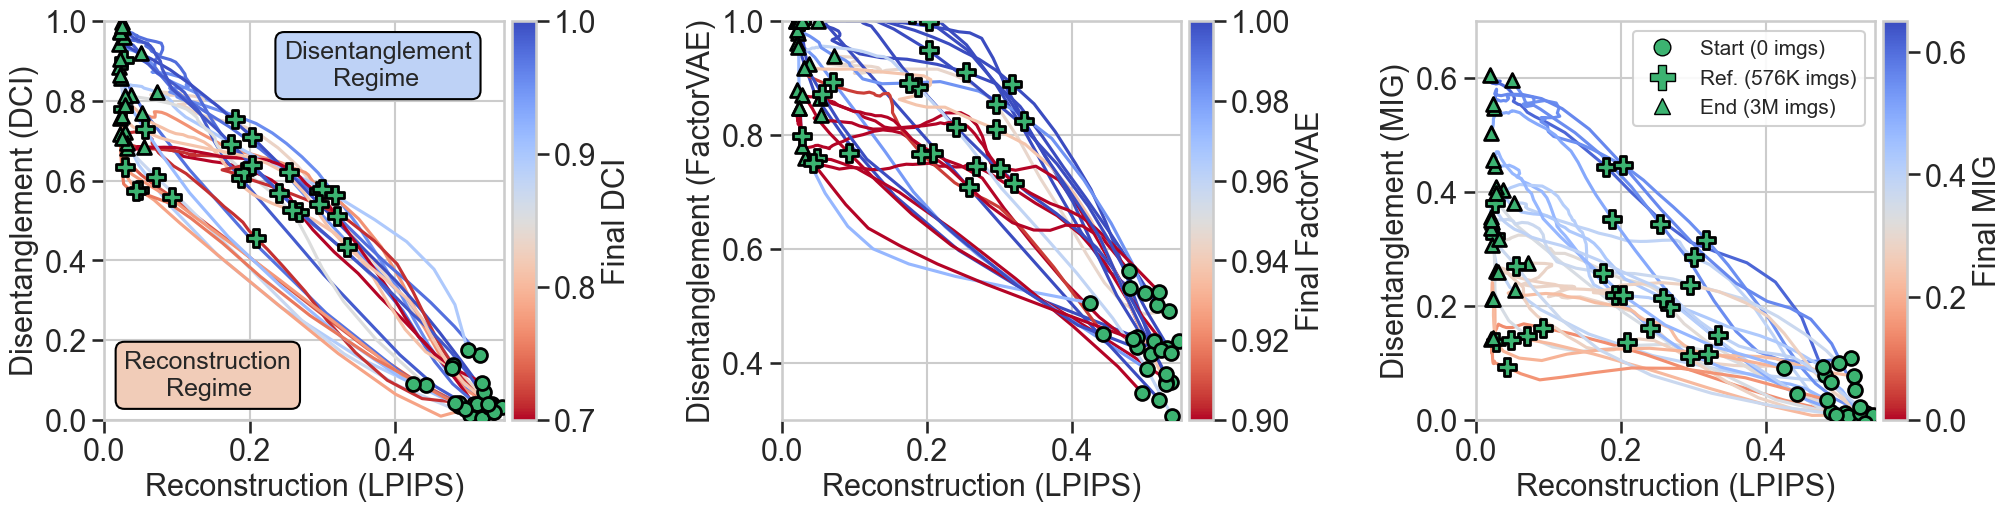

In [32]:
# path = "ckpts/vdmpp/shapes3d_early_stage"
path = "ckpts/vdmpp/shapes3d_early_stage_sech"
# model_name = "edm-3"
model_name = "sech"

metrics = {}

for folder in os.listdir(path):
    model = "_".join(folder.split("_")[2:])
    # model = folder[2:]
    if model not in metrics:
        metrics[model] = []

    df = pd.read_csv(os.path.join(path, folder, "metrics.csv"))
    metrics[model].append({
        "nimgs": df.nimgs.values,
        "LPIPS": df.lpips.values,
        "DCI": df.dci.values,
        "FactorVAE": df.factorvae.values,
        "MIG": df.mig.values,
    })

def smooth_curve(y, window=9, poly=3):
    """Savitzky–Golay smoothing with safe window handling."""
    n = len(y)
    if n < 3:
        return y
    w = min(window, n if n % 2 == 1 else n - 1)
    if w < 3:
        return y
    return savgol_filter(y, window_length=w, polyorder=min(poly, w - 1))

import numpy as np

cmap_name = "coolwarm_r"

fig, axes = plt.subplots(
    nrows=1,
    ncols=8,
    figsize=(20, 5),
    constrained_layout=True,
    gridspec_kw={
        "width_ratios": [1, 0.06, 0.1, 1, 0.06, 0.1, 1, 0.06],
    },
)

axes[2].set_axis_off()
axes[5].set_axis_off()

p_marker = 8

for model in [model_name]: #["edm-3"]:
    print(model)
    for i, (metric, lb, ub, ymin, ymax, xy, xytext) in enumerate([
        ("DCI", 0.7, 1.0, 0.0, 1.0, (0.28, 0.85), (0.5, 0.55)),
        ("FactorVAE", 0.9, 1.0, 0.3, 1.0, (0.28, 0.6), (0.5, 0.38)),
        ("MIG", 0.0, 0.65, 0.0, 0.7, (0.28, 0.6), (0.5, 0.38))
    ]):
    
        ax = axes[i * 3]
        cax = axes[i * 3 + 1]
    
        norm = plt.Normalize(vmin=lb, vmax=ub)
        cmap = plt.get_cmap(cmap_name)

        final_ys = []
    
        for vals in metrics[model]:
            x_smooth = smooth_curve(vals["LPIPS"][:-10]) #, 15, 3)
            y_smooth = smooth_curve(vals[metric][:-10])
            final_ys.append(y_smooth[-1])
            ax.plot(
                x_smooth,
                y_smooth,
                c=cmap(norm(vals[metric][-1])),
            )
    
            ax.scatter(
                x_smooth[0],
                y_smooth[0],
                c="mediumseagreen",
                marker="o",
                s=100,
                edgecolor="black",
                linewidth=2,
                zorder=50,
            )
    
            ax.scatter(
                x_smooth[p_marker],
                y_smooth[p_marker],
                marker="P",
                s=150,                # larger so visible
                c="mediumseagreen",
                edgecolor="black",
                linewidths=2,
                zorder=50,
            )
        
            # End point (final training)
            ax.scatter(
                x_smooth[-1],
                y_smooth[-1],
                c="mediumseagreen",
                marker="^",
                s=100,
                edgecolor="black",
                linewidth=2,
                zorder=50,
            )
    
        ax.set_xlim(0., .55)
        ax.set_ylim(ymin, ymax)
        ax.set_xlabel("Reconstruction (LPIPS)", fontsize=22)
        ax.set_ylabel(f"Disentanglement ({metric})", fontsize=22)
        ax.tick_params(axis="y", left=True, labelsize=22)
        ax.tick_params(axis="x", bottom=True, labelsize=22)
    
        # Create colorbar
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
        sm.set_array([])  # required for matplotlib < 3.7
        cbar = fig.colorbar(sm, cax=cax)
        cbar.set_label(f"Final {metric}", fontsize=22)
        cbar.ax.tick_params(labelsize=22)

from matplotlib.lines import Line2D

legend_handles = [
    Line2D([0], [0], marker="o", linestyle="None",
           markerfacecolor="mediumseagreen", markeredgecolor="black",
           markeredgewidth=1, markersize=12, label="Start (0 imgs)"),
    Line2D([0], [0], marker="P", linestyle="None",
           markerfacecolor="mediumseagreen", markeredgecolor="black",
           markeredgewidth=1, markersize=18, label=f"Ref. ({metrics[model_name][0]['nimgs'][p_marker] // 1000}K imgs)"),
    Line2D([0], [0], marker="^", linestyle="None",
           markerfacecolor="mediumseagreen", markeredgecolor="black",
           markeredgewidth=1, markersize=12, label="End (3M imgs)"),
]

axes[-2].legend(
    handles=legend_handles,
    loc="upper right",   # try "upper right" if it overlaps
    frameon=True,
    framealpha=0.9,
    facecolor="white",
    edgecolor="0.8",
    fontsize=15,
)

from matplotlib.offsetbox import AnchoredText
import matplotlib as mpl

colors = cmap(np.linspace(0, 1, 100))

ax_left = axes[0]

ax_left.text(
    0.45, 0.95, "Disentanglement\n       Regime",
    transform=ax_left.transAxes,
    ha="left", va="top",
    fontsize=18,
    bbox=dict(boxstyle="round,pad=0.35",
              facecolor=colors[60],
              edgecolor="0",
              alpha=1)
)

ax_left.text(
    0.05, 0.05, "Reconstruction\n      Regime",
    transform=ax_left.transAxes,
    ha="left", va="bottom",
    fontsize=18,
    bbox=dict(boxstyle="round,pad=0.35",
              facecolor=colors[40], # "white",
              edgecolor="0",
              alpha=1)
)

plt.savefig(f"analysis_traj_{model_name}.pdf")
plt.show()

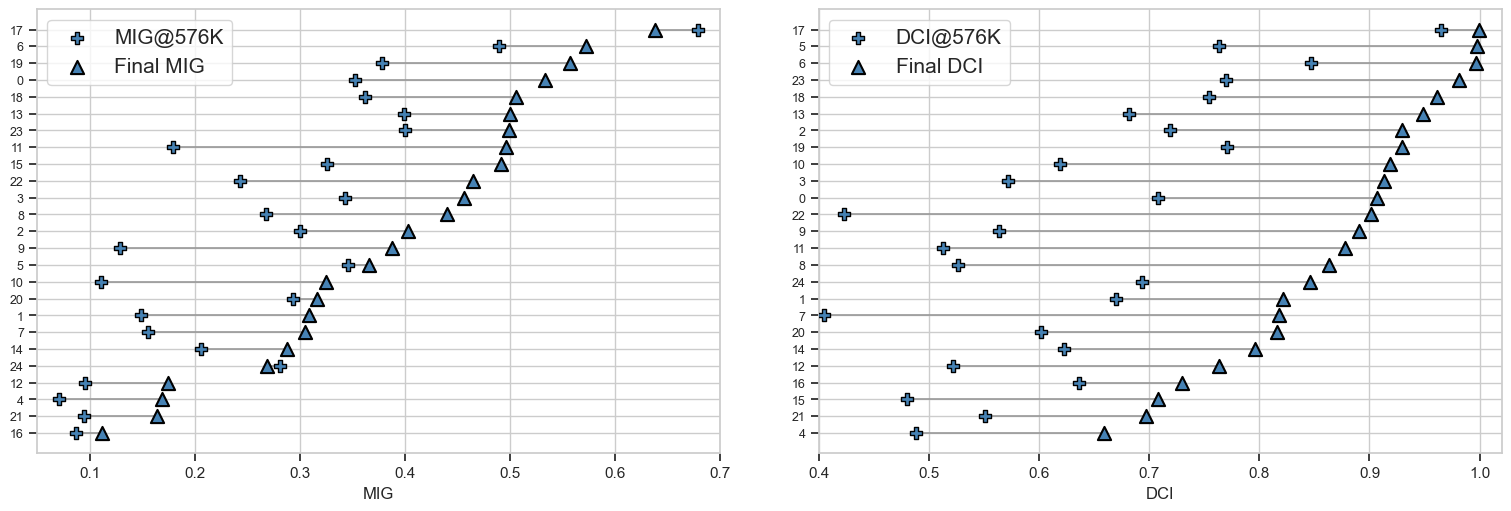

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------
# Generic helpers (unchanged)
# ----------------------------

def _nearest_index(x, target):
    x = np.asarray(x, float)
    return int(np.nanargmin(np.abs(x - target)))

def _get_xaxis(r, prefer_key=("nimgs","images_seen","img_seen","step","steps")):
    for k in prefer_key:
        if k in r:
            return np.asarray(r[k], float)
    return None

def extract_early_final_generic(
    metrics,
    model,
    metric_key="MIG",
    aux_key=None,
    target_nimgs=320_000,
    prefer_key=("nimgs","images_seen","img_seen","step","steps"),
    fallback_frac=0.1,
    name_key="Run",          # <-- new
):
    early_m, final_m = [], []
    early_aux, final_aux = [], []
    run_names = []                # <-- new

    for ri, r in enumerate(metrics[model]):
        if metric_key not in r:
            continue

        m = np.asarray(r[metric_key], float)
        if len(m) == 0:
            continue

        a = None
        if aux_key is not None:
            if aux_key not in r:
                continue
            a = np.asarray(r[aux_key], float)
            if len(a) == 0:
                continue

        xaxis = _get_xaxis(r, prefer_key=prefer_key)

        if xaxis is not None and len(xaxis) == len(m):
            idx = _nearest_index(xaxis, target_nimgs)
        else:
            idx = min(max(int(fallback_frac * (len(m) - 1)), 1), len(m) - 1)

        early_m.append(m[idx])
        final_m.append(m[-1])

        if aux_key is not None:
            early_aux.append(a[idx])
            final_aux.append(a[-1])

        # pick a run name; fallback to index if absent
        run_names.append(r.get(name_key, ri))

    early_m = np.asarray(early_m)
    final_m = np.asarray(final_m)
    run_names = np.asarray(run_names)

    if aux_key is None:
        return early_m, final_m, run_names, None, None

    return early_m, final_m, run_names, np.asarray(early_aux), np.asarray(final_aux)

# ----------------------------
# Plot: single figure with two axes (MIG + DCI)
# ----------------------------

def plot_lollipop_two_axes(
    metrics,
    model,
    target_nimgs=512_000,
    prefer_key=("nimgs","images_seen","img_seen","step","steps"),
    xlims={"MIG": (0.05, 0.7), "DCI": (0.4, 1.02)},
    titlestr=None,
    bottom_k=7,
    top_k=7,
    draw_separators=True,
    separator_color="0.2",
    line_color="0.5",
):
    fig, axes = plt.subplots(
        nrows=1,
        ncols=3,
        figsize=(15, 5),
        sharey=False,
        constrained_layout=True,
        gridspec_kw={
            "width_ratios": [1, 0.06, 1],
        },
    )

    axes[1].set_axis_off()

    for ax, metric_key in zip([axes[0], axes[2]], ["MIG", "DCI"]):
        early, final, run_names, _, _ = extract_early_final_generic(
            metrics, model,
            metric_key=metric_key,
            aux_key=None,
            target_nimgs=target_nimgs,
            prefer_key=prefer_key,
            name_key="run_name",
        )
        
        order = np.argsort(final)
        y = np.arange(len(final))
        
        ax.set_yticks(y)
        ax.set_yticklabels(run_names[order], fontsize=9)

        if len(early) < 3:
            ax.set_title(f"{metric_key}: not enough runs")
            continue

        order = np.argsort(final)
        y = np.arange(len(final))

        # grey connecting lines
        for i, idx in enumerate(order):
            ax.plot([early[idx], final[idx]], [i, i],
                    color=line_color, linewidth=1.2, zorder=1)

        # early and final markers
        ax.scatter(early[order], y, s=85,
                   marker="P", c="steelblue",
                   edgecolor="black", linewidths=1, zorder=3,
                   label=f"{metric_key}@{int(target_nimgs/1000)}K")

        ax.scatter(final[order], y, s=90,
                   marker="^", c="steelblue",
                   edgecolor="black", linewidths=1.5, zorder=4,
                   label=f"Final {metric_key}")

        # x-lims
        if metric_key in xlims:
            ax.set_xlim(*xlims[metric_key])

        ax.set_xlabel(metric_key)
        ax.legend(loc="upper left", fontsize=15)
        ax.tick_params(axis="y", left=True)
        ax.tick_params(axis="x", bottom=True)

    plt.show()

model = "edm-3"
target_nimgs = 576_000

plot_lollipop_two_axes(
    metrics,
    model=model,
    target_nimgs=target_nimgs,
    bottom_k=7,
    top_k=7,
    draw_separators=True,
    line_color="0.6",
)

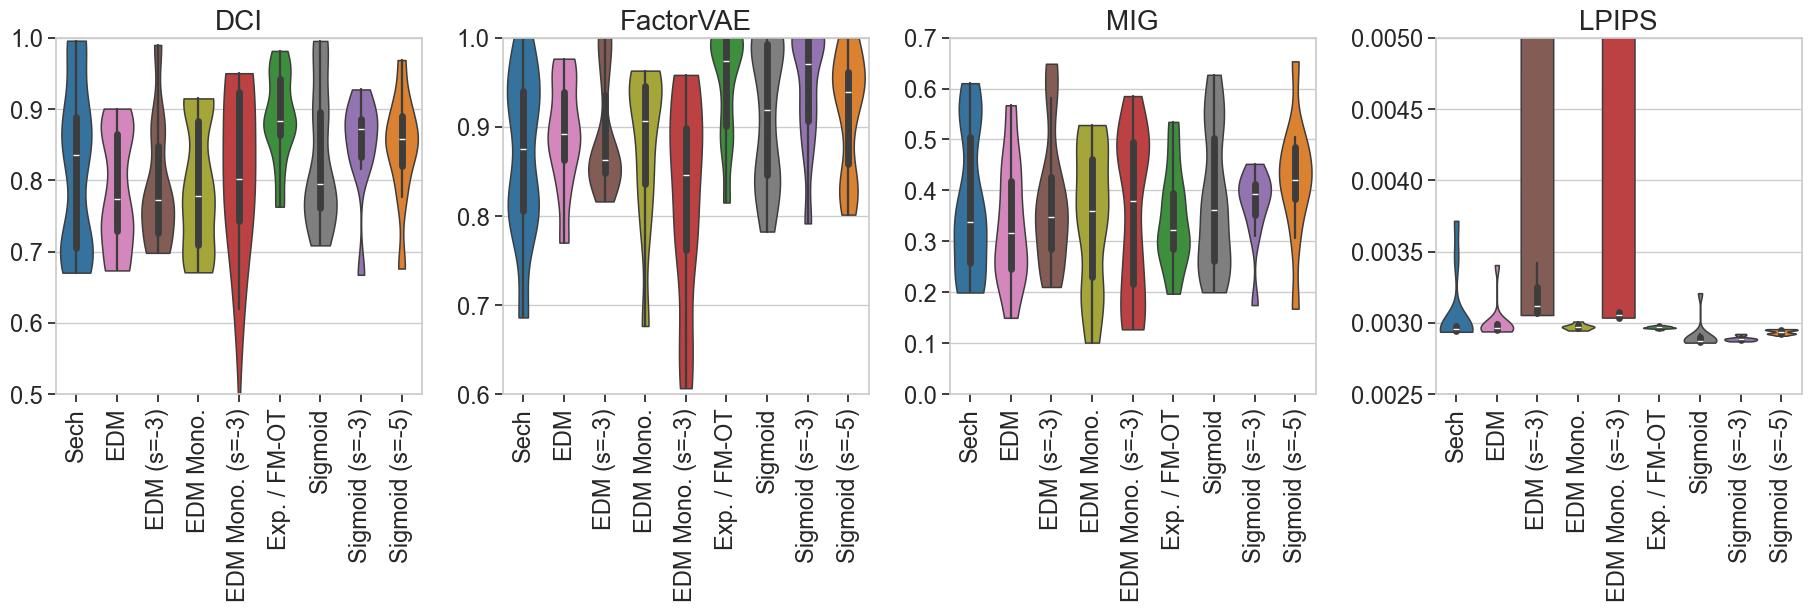

In [152]:
import os
import numpy as np
import pandas as pd

# path = "ckpts/vdmpp_deep_longer_stable/shapes3d"
path = "ckpts/final/shapes3d"

metrics = {}

metric_cols = {
    "LPIPS": "lpips",
    "DCI": "dci",
    "FactorVAE": "factorvae",
    "MIG": "mig",
}
model_names = {
    "sech": "Sech",
    "edm": "EDM",
    "edm-3": "EDM (s=-3)",
    "edm_mono": "EDM Mono.",
    "edm_mono-3": "EDM Mono. (s=-3)",
    "exp": "Exp. / FM-OT",
    "sigmoid": "Sigmoid",
    "sigmoid-3": "Sigmoid (s=-3)",
    "sigmoid-5": "Sigmoid (s=-5)",
}

for folder in os.listdir(path):
    folder_path = os.path.join(path, folder)
    if not os.path.isdir(folder_path):
        continue

    model_full_name = folder.split("/")[-1].split("_")

    if len(model_full_name[1:]) > 0:
        model = "_".join(model_full_name[1:])
    else:
        if model_full_name[0].endswith("A"):
            model = "sech"
        else:
            continue

    if not model:
        continue

    csv_path = os.path.join(folder_path, "metrics.csv")
    if not os.path.exists(csv_path):
        continue

    df = pd.read_csv(csv_path)

    # print("model:", model)
    if model not in metrics:
        metrics[model] = {k: [] for k in metric_cols.keys()}

    for pretty_name, col in metric_cols.items():
        if col in df.columns and len(df[col]) > 0:
            val = df[col].values[-1]
            if np.isfinite(val):
                metrics[model][pretty_name].append(float(val))

rows = []

for model, model_metrics in metrics.items():
    for metric_name, values in model_metrics.items():
        for v in values:
            rows.append({
                "Model": model_names[model],
                "Metric": metric_name,
                "Value": v,
            })

df_long = pd.DataFrame(rows)

import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="whitegrid")

fig, axes = plt.subplots(1, 7, figsize=(18, 6), constrained_layout=True,
                            gridspec_kw={
        "width_ratios": [1, 0.05, 1, 0.05, 1, 0.05, 1],
    },
                        )

metric_order = [("DCI", 0.5, 1.0), ("FactorVAE", 0.6, 1.0), ("MIG", 0, 0.7), ("LPIPS", 0.0025, 0.005)]

for ax, (metric_name, lb, ub) in zip([axes[0], axes[2], axes[4], axes[6]], metric_order):
    subset = df_long[df_long["Metric"] == metric_name]

    sns.violinplot(
        data=subset,
        x="Model",
        y="Value",
        ax=ax,
        inner="box",     # show median + IQR
        cut=0,
        hue="Model",
        order=model_names.values(),
        bw_adjust=0.6,
        linewidth=1.1,
        saturation=0.7,
        palette="tab10",
    )

    ax.set_title(metric_name, fontsize=20)
    ax.tick_params(axis="x", labelsize=17, rotation=90)
    ax.tick_params(axis="y", labelsize=17)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_ylim(bottom=lb, top=ub)
    ax.tick_params(axis="y", left=True)
    ax.tick_params(axis="x", bottom=True)

axes[1].set_axis_off()
axes[3].set_axis_off()
axes[5].set_axis_off()

fig.savefig("analysis_weighting_violins.pdf")
plt.show()

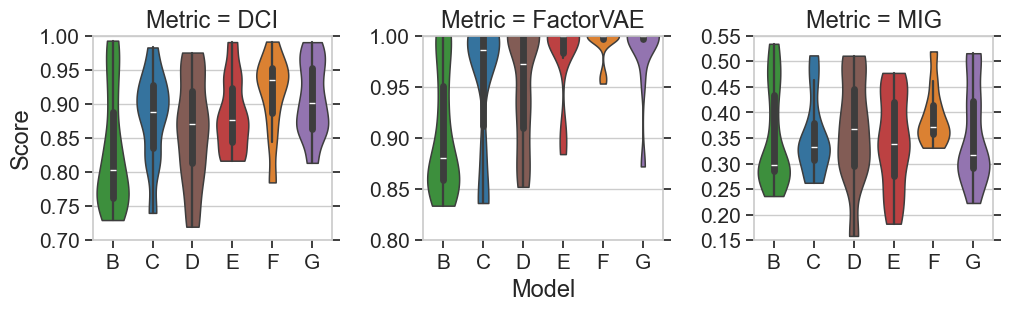

In [96]:
import os
import numpy as np
import pandas as pd

path = "ckpts/paper/shapes3d"

metrics = {}

metric_cols = {
    "LPIPS": "lpips",
    "DCI": "dci",
    "FactorVAE": "factorvae",
    "MIG": "mig",
}
model_names = {
    # "encdiff_baseline": "B",
    "film": "B",
    "film_sigmoid": "C",
    "film_sigmoid_resunet": "D",
    "film_sigmoid_resunet_bw": "E",
    "film_sigmoid_resunet_bw_gr": "F",
    "film_sigmoid_resunet_bw_gr_hyb": "G",
    # "film_sigmoid_m2": "E",
    # "film_sigmoid_exp": "E2",
    # "film_sigmoid_m1": "D",
    # "film_sigmoid_m1_bw_gr": "M",
    # "film_sigmoid_m1_resunet": "E",
    # "film_sigmoid_m1_resunet_bw": "F",
    # "film_sigmoid_m1_resunet_bw_gr": "G",
    # "film_sigmoid_m1_resunet_bw3_gr": "H",
}

for folder in os.listdir(path):
    folder_path = os.path.join(path, folder)
    if not os.path.isdir(folder_path):
        continue

    model = folder[2:]
    if model not in model_names.keys():
        continue

    csv_path = os.path.join(folder_path, "metrics.csv")
    if not os.path.exists(csv_path):
        continue

    df = pd.read_csv(csv_path)
    
    if model not in metrics:
        metrics[model] = {k: [] for k in metric_cols.keys()}

    for pretty_name, col in metric_cols.items():
        if col in df.columns and len(df[col]) > 0:
            val = df[col].values[-1] #.values[-1]
            if np.isfinite(val):
                metrics[model][pretty_name].append(float(val))

rows = []

for model, model_metrics in metrics.items():
    for metric_name, values in model_metrics.items():
        for v in values:
            rows.append({
                "Model": model_names[model],
                "Metric": metric_name,
                "Value": v,
            })

df_long = pd.DataFrame(rows)

import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="whitegrid")

metric_order = [("DCI", 0.75, 1.0, 7), ("FactorVAE", 0.8, 1.0, 7), ("MIG", 0.15, 0.6, 6)] #, ("LPIPS", 0.0005, 0.0015, 9)]

fig, axes = plt.subplots(
    1, len(metric_order) * 2 - 1,
    figsize=(10, 3),
    constrained_layout=True,
    gridspec_kw={
        "width_ratios": [1, 0.05] * (len(metric_order) - 1) + [1], #, 1, 0.05, 1, 0.05, 1],
    },
)

for ax, (metric_name, lb, ub, steps) in zip([axes[i * 2] for i in range(len(metric_order))], metric_order):
    subset = df_long[df_long["Metric"] == metric_name]

    sns.violinplot(
        data=subset,
        x="Model",
        y="Value",
        ax=ax,
        inner="box",     # show median + IQR
        cut=0,
        # hue="Model",
        order=model_names.values(),
        bw_adjust=0.6,
        linewidth=1.1,
        saturation=0.7,
        palette="tab10",
        hue="Model",
        # legend=False,
    )

    ax.set_title(f"Metric = {metric_name}", fontsize=17)
    ax.tick_params(axis="x", labelsize=15)
    ax.tick_params(axis="y", labelsize=15)
    ax.set_xlabel("")
    ax.set_ylabel("")
    # ax.set_ylim(bottom=lb, top=ub)
    ax.tick_params(axis="y", left=True, right=True)
    ax.tick_params(axis="x", bottom=True)
    # ax.set_yticks(np.linspace(lb, ub, steps))   # more lines

    if metric_name == "DCI":
        ax.set_ylim(0.7, 1.0)
        ax.set_yticks([0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0])
    
    elif metric_name == "FactorVAE":
        ax.set_ylim(0.8, 1.0)
        ax.set_yticks([0.8, 0.85, 0.9, 0.95, 1.0])
    
    elif metric_name == "MIG":
        ax.set_ylim(0.15, 0.55)
        ax.set_yticks([0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55])

for i in range(len(metric_order) - 1):
    axes[i * 2 + 1].set_axis_off()

axes[2].set_xlabel("Model", fontsize=17)
axes[0].set_ylabel("Score", fontsize=17)

fig.savefig("analysis_violins_ablations.pdf")
plt.show()

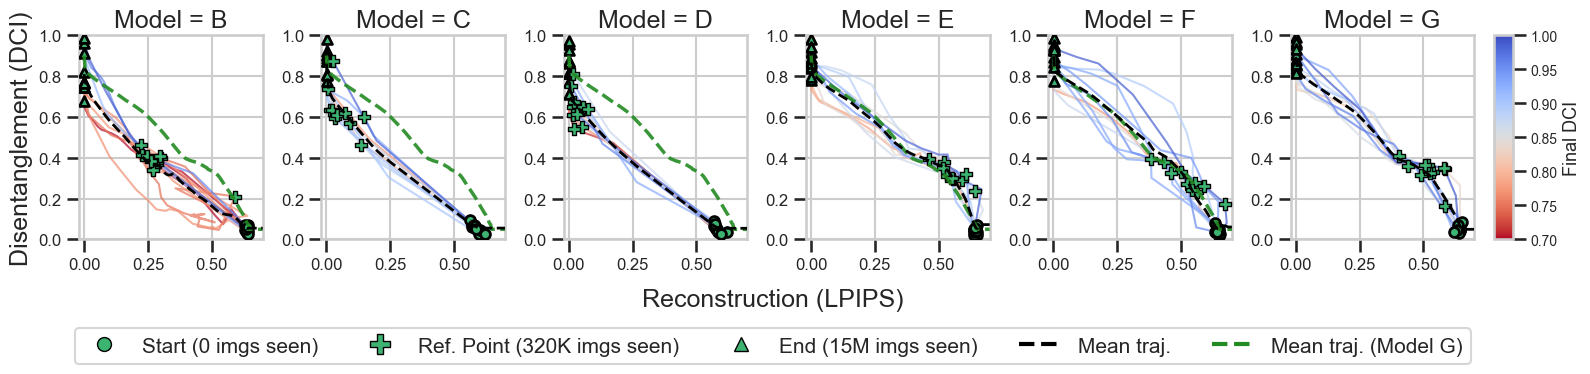

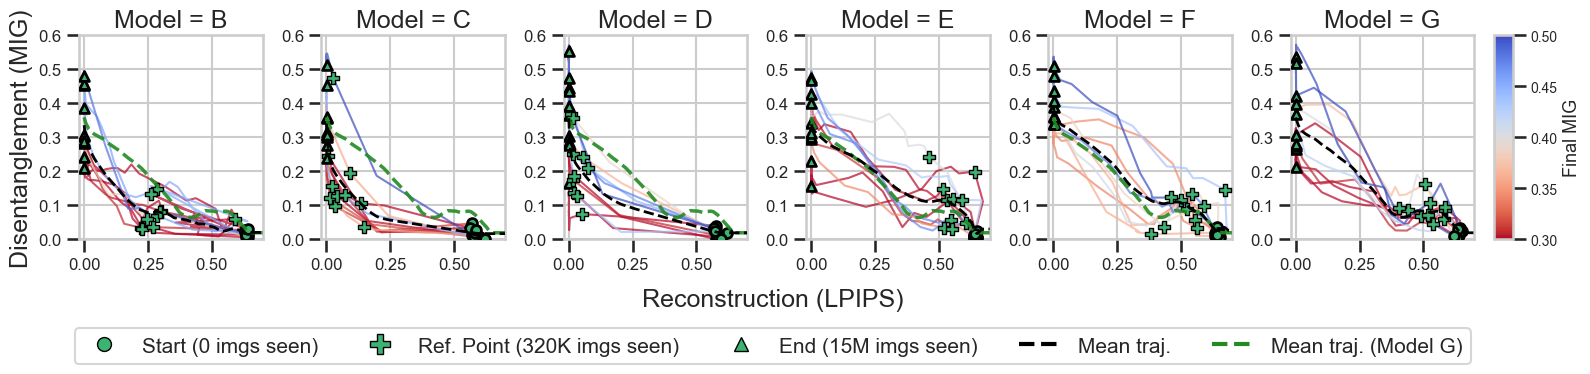

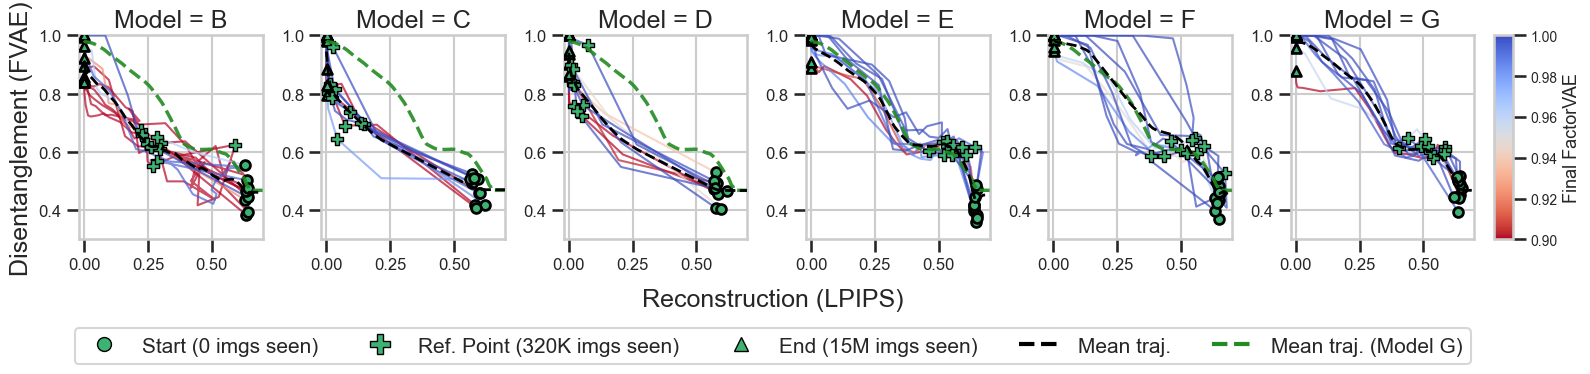

In [89]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.signal import savgol_filter
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("tab10")

path = "ckpts/paper/shapes3d"
# path = "ckpts/paper/mpi3d"
# path = "ckpts/paper/cars3d"
metrics = {}

for folder in os.listdir(path):
    folder_path = os.path.join(path, folder)
    if not os.path.isdir(folder_path):
        continue

    model = folder[2:]
    if model not in metrics:
        metrics[model] = []

    csv_path = os.path.join(folder_path, "metrics.csv")
    if not os.path.exists(csv_path):
        continue

    df = pd.read_csv(csv_path)
    metrics[model].append({
        "LPIPS": df.lpips.values,
        "DCI": df.dci.values,
        "FactorVAE": df.factorvae.values,
        "MIG": df.mig.values,
    })


def smooth_curve(y, window=9, poly=3):
    n = len(y)
    if n < 3:
        return y
    w = min(window, n if n % 2 == 1 else n - 1)
    if w < 3:
        return y
    return savgol_filter(y, window_length=w, polyorder=min(poly, w - 1))


def get_mean_trajectory(model, metric, metrics, ref_point=2, num_points=200, x_max=0.7):
    x_grid = np.linspace(0.0, x_max, num_points)
    ys_interp = []

    for vals in metrics.get(model, []):
        if len(vals["LPIPS"]) < ref_point:
            continue

        x = np.array(vals["LPIPS"])
        y = np.array(vals[metric])

        if len(x) > 40:
            x = x[:-15]
            y = y[:-15]

        # make x increasing for interpolation
        if x[0] > x[-1]:
            x = x[::-1]
            y = y[::-1]

        x_unique, idx = np.unique(x, return_index=True)
        y_unique = y[idx]

        if len(x_unique) > 2:
            y_interp = np.interp(x_grid, x_unique, y_unique)
            ys_interp.append(y_interp)

    if len(ys_interp) == 0:
        return None, None, None

    ys_interp = np.stack(ys_interp, axis=0)
    y_mean = ys_interp.mean(axis=0)
    y_std = ys_interp.std(axis=0)
    return x_grid, y_mean, y_std


cmap_name = "coolwarm_r"

ml = [
    # ("encdiff_baseline", "-", "B"),
    ("film", "-", "B"),
    ("film_sigmoid", "-", "C"),
    ("film_sigmoid_resunet", "-", "D"),
    ("film_sigmoid_resunet_bw", "-", "E"),
    ("film_sigmoid_resunet_bw_gr", "-", "F"),
    ("film_sigmoid_resunet_bw_gr_hyb", "-", "G"),
    # ("film_sigmoid_resunet_bw_gr_20", "-", "Final"),
    # ("film_sigmoid_resunet_bw3_gr_20", "-", "Final2"),
]

# ml = [
#     # ("encdiff_baseline", "-", "B"),
#     ("film", "-", "B"),
#     # ("film_sigmoid", "-", "C"),
#     ("film_sigmoid_resunet", "-", "D"),
#     # ("film_sigmoid_resunet_bw", "-", "E"),
#     ("film_sigmoid_resunet_bw_gr", "-", "F"),
#     # ("film_sigmoid_resunet_bw_gr_hyb", "-", "H"),
# ]

ref_point = 2


for metric, lb, ub, ymin, ymax, xy, xytext in [
    ("DCI", 0.7, 1.0, 0.0, 1.0, (0.28, 0.85), (0.5, 0.55)),
    ("MIG", 0.3, 0.5, 0.0, 0.6, (0.28, 0.6), (0.5, 0.38)),
    ("FactorVAE", 0.9, 1.0, 0.3, 1.0, (0.28, 0.6), (0.5, 0.38)),
]:
    # Reference line
    ref_model = ml[-1][0] # "film_sigmoid_resunet_bw_gr"  # G
    ref_name = ml[-1][2] # "G"
    xg_ref, yg_ref_mean, yg_ref_std = get_mean_trajectory(
        ref_model, metric, metrics, ref_point=ref_point, num_points=200, x_max=0.7
    )

    width_ratios = [1, 0.1] * len(ml)
    # width_ratios[-1] = 0.06
    
    fig, axes = plt.subplots(
        nrows=1,
        ncols=len(ml) * 2,
        figsize=(18.5, 3),
        # constrained_layout=True,
        gridspec_kw={"width_ratios": width_ratios},
    )

    cax = axes[-1]

    norm = plt.Normalize(vmin=lb, vmax=ub)
    cmap = plt.get_cmap(cmap_name)

    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cax)
    cbar.set_label(f"Final {metric}", fontsize=13)
    cbar.ax.tick_params(labelsize=10)

    legend_handles = [
        Line2D([0], [0], marker="o", linestyle="None",
               markerfacecolor="mediumseagreen", markeredgecolor="black",
               markeredgewidth=1, markersize=10, label="Start (0 imgs seen)"),
        Line2D([0], [0], marker="P", linestyle="None",
               markerfacecolor="mediumseagreen", markeredgecolor="black",
               markeredgewidth=1, markersize=15, label="Ref. Point (320K imgs seen)"),
        Line2D([0], [0], marker="^", linestyle="None",
               markerfacecolor="mediumseagreen", markeredgecolor="black",
               markeredgewidth=1, markersize=10, label="End (15M imgs seen)"),
        Line2D([0], [0], color="black", linestyle="--", linewidth=3,
               label="Mean traj."),
        Line2D([0], [0], color="forestgreen", linestyle="--", linewidth=3,
               label=f"Mean traj. (Model {ref_name})"),
    ]
    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=len(legend_handles),
        frameon=True,
        fontsize=15,
        bbox_to_anchor=(0.5, -0.25),
    )
    fig.subplots_adjust(bottom=0.2)

    fig.text(
        0.5,              # x position (center of figure)
        0.0,             # y position (adjust as needed)
        "Reconstruction (LPIPS)",
        ha="center",
        va="center",
        fontsize=18,
    )

    for i, (model, linestyle, name) in enumerate(ml):        
        ax = axes[i * 2]
        ax.set_xlim(-0.02, 0.7)
        # ax.set_xlabel("Reconstruction (LPIPS)")

        ax.set_title(f"Model = {name}", fontsize=18)
        
        spacer = axes[i * 2 + 1]
        if i != len(ml) - 1:
            spacer.set_axis_off()

        ax.set_ylim(ymin, ymax) 
        if i == 0:
            ax.set_ylabel(f"Disentanglement ({'FVAE' if metric == 'FactorVAE' else metric})", fontsize=18)

        # if i != 0 or i == len(axes) - 1:
        #     ax.tick_params(labelleft=False)

        ax.tick_params(axis="y", left=True, labelsize=12) #, right=True)
        ax.tick_params(axis="x", bottom=True, labelsize=12)
        
        # -------------------------
        # 1) Plot all individual seed trajectories
        # -------------------------
        for vals in metrics.get(model, []):
            if len(vals["LPIPS"]) <= ref_point:
                continue
                
            x_smooth = np.array(vals["LPIPS"])
            y_smooth = np.array(vals[metric])
            if len(x_smooth) > 40:
                x_smooth = x_smooth[:-15]
                y_smooth = y_smooth[:-15]

            ax.plot(
                x_smooth,
                y_smooth,
                c=cmap(norm(y_smooth[-1])),
                linestyle=linestyle,
                linewidth=1.5,
                alpha=0.7,
                zorder=int(y_smooth[-1] * 100),
            )

            ax.scatter(
                x_smooth[0],
                y_smooth[0],
                c="mediumseagreen",
                marker="o",
                s=50,
                edgecolor="black",
                linewidth=2,
                zorder=1000,
            )

            ax.scatter(
                x_smooth[ref_point],
                y_smooth[ref_point],
                marker="P",
                s=80,
                c="mediumseagreen",
                edgecolor="black",
                linewidths=1,
                zorder=1000,
            )

            ax.scatter(
                x_smooth[-1],
                y_smooth[-1],
                c="mediumseagreen",
                marker="^",
                s=50,
                edgecolor="black",
                linewidth=2,
                zorder=1000,
            )

        if model != ref_model and xg_ref is not None:
            ax.plot(
                xg_ref,
                yg_ref_mean,
                color="forestgreen", #"dimgray",
                linewidth=2.5,
                linestyle="--",
                alpha=0.9,
                zorder=1900,
                # label=f"{ref_name} mean",
            )

        # -------------------------
        # 2) Compute and plot one mean trajectory
        # -------------------------
        yg, yg_mean, _ = get_mean_trajectory(
            model, metric, metrics, ref_point=ref_point, num_points=200, x_max=0.7
        )

        if yg is not None and len(yg) > 0:
            ax.plot(
                smooth_curve(yg),
                smooth_curve(yg_mean),
                color="black",
                linewidth=2,
                linestyle="--",
                zorder=2000,
                label="Mean trajectory",
            )
    
    plt.savefig(f"{metric}_ablations_trajectories.pdf", dpi=500, bbox_inches="tight")
    plt.show()

film
film_sigmoid_resunet_bw_gr_hyb


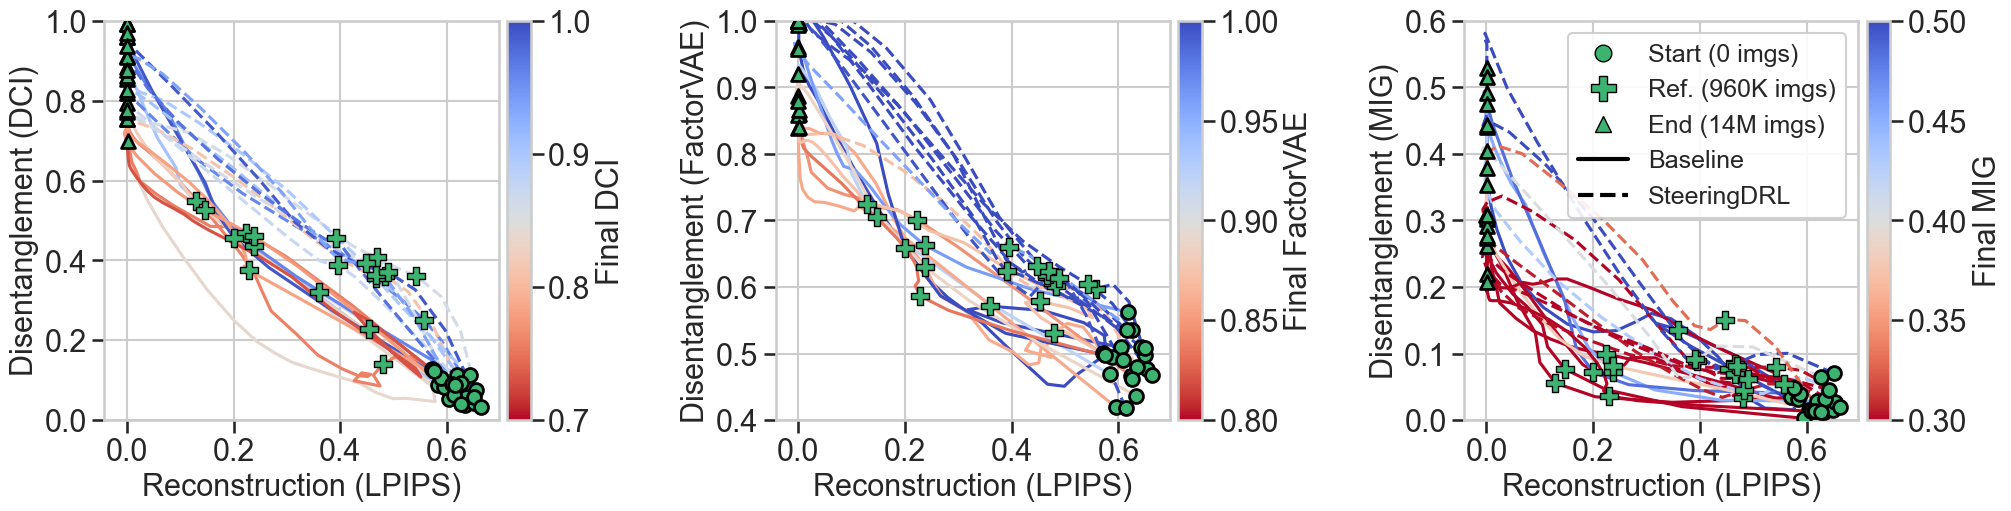

In [101]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.signal import savgol_filter
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("tab10")

path = "ckpts/paper/shapes3d"
metrics = {}

for folder in os.listdir(path):
    folder_path = os.path.join(path, folder)
    if not os.path.isdir(folder_path):
        continue

    model = folder[2:]
    if model not in metrics:
        metrics[model] = []

    csv_path = os.path.join(folder_path, "metrics.csv")
    if not os.path.exists(csv_path):
        continue

    df = pd.read_csv(csv_path)
    metrics[model].append({
        "nimgs": df.nimgs.values,
        "LPIPS": df.lpips.values,
        "DCI": df.dci.values,
        "FactorVAE": df.factorvae.values,
        "MIG": df.mig.values,
    })

def smooth_curve(y, window=9, poly=3):
    """Savitzky–Golay smoothing with safe window handling."""
    n = len(y)
    if n < 3:
        return y
    w = min(window, n if n % 2 == 1 else n - 1)
    if w < 3:
        return y
    return savgol_filter(y, window_length=w, polyorder=min(poly, w - 1))

import numpy as np

cmap_name = "coolwarm_r"

# fig, axes = plt.subplots(
#     nrows=1,
#     ncols=8,
#     figsize=(20, 5),
#     constrained_layout=True,
#     gridspec_kw={
#         "width_ratios": [1, 0.06, 0.05, 1, 0.06, 0.05, 1, 0.06],
#     },
# )
fig, axes = plt.subplots(
    nrows=1,
    ncols=8,
    figsize=(20, 5),
    constrained_layout=True,
    gridspec_kw={
        "width_ratios": [1, 0.06, 0.1, 1, 0.06, 0.1, 1, 0.06],
    },
)

axes[2].set_axis_off()
axes[5].set_axis_off()

p_marker = 3

model_names = [("film", "-"), ("film_sigmoid_resunet_bw_gr_hyb", "--")]

for model, linestyle in model_names: #["edm-3"]:
    print(model)
    for i, (metric, lb, ub, ymin, ymax, xy, xytext) in enumerate([
        # ("DCI", 0.7, 1.0, 0.0, 1.0, (0.28, 0.85), (0.5, 0.55)),
        # ("FactorVAE", 0.9, 1.0, 0.3, 1.0, (0.28, 0.6), (0.5, 0.38)),
        # ("MIG", 0.0, 0.65, 0.0, 0.7, (0.28, 0.6), (0.5, 0.38))
        ("DCI", 0.7, 1.0, 0.0, 1.0, (0.28, 0.85), (0.5, 0.55)),
        ("FactorVAE", 0.8, 1.0, 0.4, 1.0, (0.28, 0.6), (0.5, 0.38)),
        ("MIG", 0.3, 0.5, 0.0, 0.6, (0.28, 0.6), (0.5, 0.38)),
    ]):
    
        ax = axes[i * 3]
        cax = axes[i * 3 + 1]
    
        norm = plt.Normalize(vmin=lb, vmax=ub)
        cmap = plt.get_cmap(cmap_name)

        final_ys = []
    
        for vals in metrics[model]:
            x_smooth = smooth_curve(vals["LPIPS"][:-10], window=9)
            y_smooth = smooth_curve(vals[metric][:-10], window=9)
            # x_smooth = vals["LPIPS"][:-10]
            # y_smooth = vals[metric][:-10]
            final_ys.append(y_smooth[-1])
            ax.plot(
                x_smooth,
                y_smooth,
                c=cmap(norm(vals[metric][-1])),
                linestyle=linestyle,
            )
    
            ax.scatter(
                x_smooth[0],
                y_smooth[0],
                c="mediumseagreen",
                marker="o",
                s=100,
                edgecolor="black",
                linewidth=2,
                zorder=50,
            )
    
            ax.scatter(
                x_smooth[p_marker],
                y_smooth[p_marker],
                marker="P",
                s=150,                # larger so visible
                c="mediumseagreen",
                edgecolor="black",
                linewidths=1,
                zorder=50,
            )
        
            # End point (final training)
            ax.scatter(
                x_smooth[-1],
                y_smooth[-1],
                c="mediumseagreen",
                marker="^",
                s=100,
                edgecolor="black",
                linewidth=2,
                zorder=50,
            )
    
        # ax.set_xlim(0., .55)
        ax.set_ylim(ymin, ymax)
        ax.set_xlabel("Reconstruction (LPIPS)", fontsize=22)
        ax.set_ylabel(f"Disentanglement ({metric})", fontsize=22)
        ax.tick_params(axis="y", left=True, labelsize=22)
        ax.tick_params(axis="x", bottom=True, labelsize=22)
    
        # Create colorbar
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
        sm.set_array([])  # required for matplotlib < 3.7
        cbar = fig.colorbar(sm, cax=cax)
        cbar.set_label(f"Final {metric}", fontsize=22)
        cbar.ax.tick_params(labelsize=22)

from matplotlib.lines import Line2D

legend_handles = [
    Line2D([0], [0], marker="o", linestyle="None",
           markerfacecolor="mediumseagreen", markeredgecolor="black",
           markeredgewidth=1, markersize=12, label="Start (0 imgs)"),
    Line2D([0], [0], marker="P", linestyle="None",
           markerfacecolor="mediumseagreen", markeredgecolor="black",
           markeredgewidth=1, markersize=18, label=f"Ref. ({metrics[model_names[0][0]][0]['nimgs'][p_marker] // 1000}K imgs)"),
    Line2D([0], [0], marker="^", linestyle="None",
           markerfacecolor="mediumseagreen", markeredgecolor="black",
           markeredgewidth=1, markersize=12, label=f"End ({metrics[model_names[0][0]][0]['nimgs'][-1] // 1_000_000}M imgs)"),
    Line2D([0], [0], color="black", linestyle=model_names[0][1], linewidth=3, label="Baseline"),
    Line2D([0], [0], color="black", linestyle=model_names[1][1], linewidth=3, label="SteeringDRL"),
]

axes[-2].legend(
    handles=legend_handles,
    loc="upper right",   # try "upper right" if it overlaps
    frameon=True,
    framealpha=0.9,
    facecolor="white",
    edgecolor="0.8",
    fontsize=18,
)

plt.savefig(f"ablation_analysis_2_traj.pdf")
plt.show()

film
film_sigmoid_m2


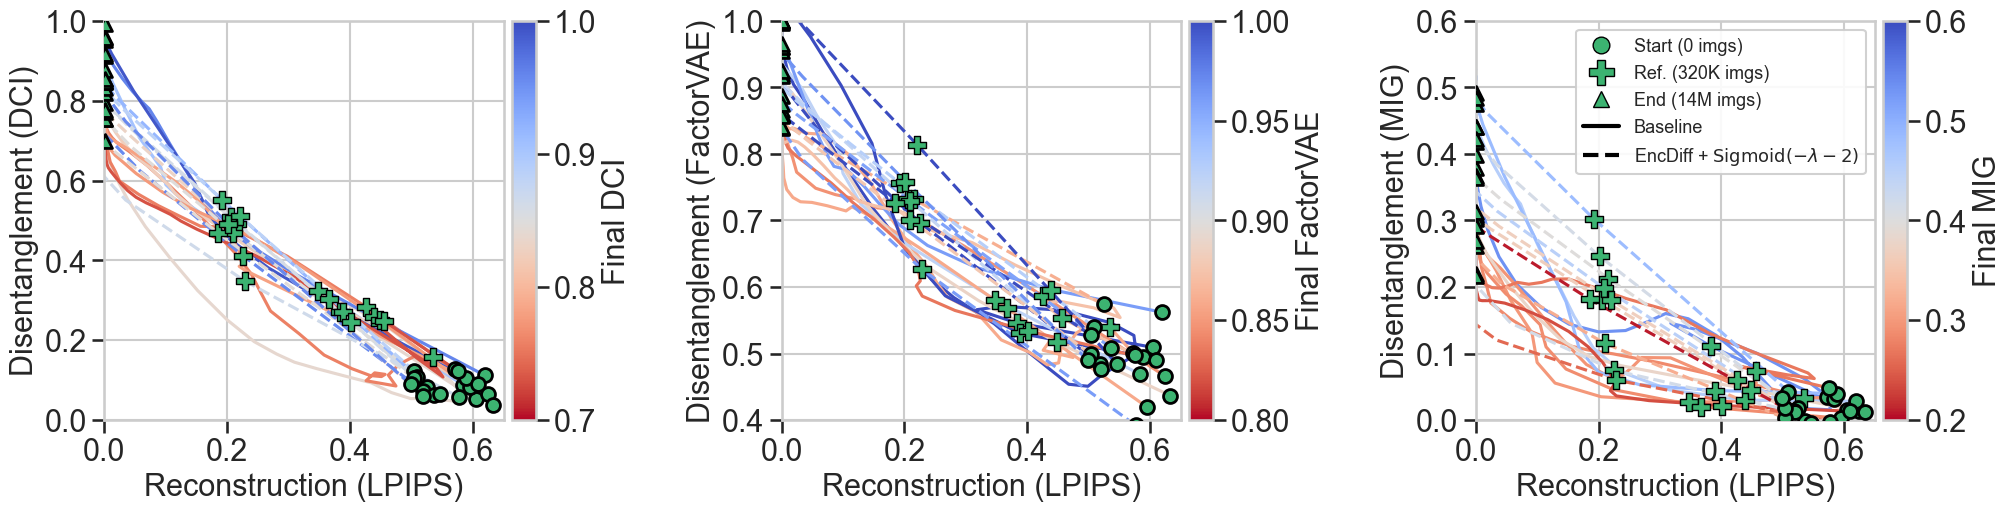

In [106]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.signal import savgol_filter
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("tab10")

paths = ["ckpts/paper/shapes3d", "ckpts/final/shapes3d"]
metrics = {}

for path in paths:
    for folder in os.listdir(path):
        folder_path = os.path.join(path, folder)
        if not os.path.isdir(folder_path):
            continue
    
        model = folder[2:]
        if model not in metrics:
            metrics[model] = []
    
        csv_path = os.path.join(folder_path, "metrics.csv")
        if not os.path.exists(csv_path):
            continue
    
        df = pd.read_csv(csv_path)
        metrics[model].append({
            "nimgs": df.nimgs.values,
            "LPIPS": df.lpips.values,
            "DCI": df.dci.values,
            "FactorVAE": df.factorvae.values,
            "MIG": df.mig.values,
        })

def smooth_curve(y, window=9, poly=3):
    """Savitzky–Golay smoothing with safe window handling."""
    n = len(y)
    if n < 3:
        return y
    w = min(window, n if n % 2 == 1 else n - 1)
    if w < 3:
        return y
    return savgol_filter(y, window_length=w, polyorder=min(poly, w - 1))

import numpy as np

cmap_name = "coolwarm_r"

# fig, axes = plt.subplots(
#     nrows=1,
#     ncols=8,
#     figsize=(20, 5),
#     constrained_layout=True,
#     gridspec_kw={
#         "width_ratios": [1, 0.06, 0.05, 1, 0.06, 0.05, 1, 0.06],
#     },
# )
fig, axes = plt.subplots(
    nrows=1,
    ncols=8,
    figsize=(20, 5),
    constrained_layout=True,
    gridspec_kw={
        "width_ratios": [1, 0.06, 0.1, 1, 0.06, 0.1, 1, 0.06],
    },
)

axes[2].set_axis_off()
axes[5].set_axis_off()

p_marker = 1

model_names = [("film", "-"), ("film_sigmoid_m2", "--")]

for model, linestyle in model_names: #["edm-3"]:
    print(model)
    for i, (metric, lb, ub, ymin, ymax, xy, xytext) in enumerate([
        ("DCI", 0.7, 1.0, 0.0, 1.0, (0.28, 0.85), (0.5, 0.55)),
        ("FactorVAE", 0.8, 1.0, 0.4, 1.0, (0.28, 0.6), (0.5, 0.38)),
        ("MIG", 0.2, 0.6, 0.0, 0.6, (0.28, 0.6), (0.5, 0.38)),
    ]):
    
        ax = axes[i * 3]
        cax = axes[i * 3 + 1]
    
        norm = plt.Normalize(vmin=lb, vmax=ub)
        cmap = plt.get_cmap(cmap_name)

        final_ys = []
    
        for vals in metrics[model]:
            x_smooth = smooth_curve(vals["LPIPS"][:-10], window=9)
            y_smooth = smooth_curve(vals[metric][:-10], window=9)
            # x_smooth = vals["LPIPS"][:-10]
            # y_smooth = vals[metric][:-10]
            final_ys.append(y_smooth[-1])
            ax.plot(
                x_smooth,
                y_smooth,
                c=cmap(norm(vals[metric][-1])),
                linestyle=linestyle,
            )
    
            ax.scatter(
                x_smooth[0],
                y_smooth[0],
                c="mediumseagreen",
                marker="o",
                s=100,
                edgecolor="black",
                linewidth=2,
                zorder=50,
            )
    
            ax.scatter(
                x_smooth[p_marker],
                y_smooth[p_marker],
                marker="P",
                s=150,                # larger so visible
                c="mediumseagreen",
                edgecolor="black",
                linewidths=1,
                zorder=50,
            )
        
            # End point (final training)
            ax.scatter(
                x_smooth[-1],
                y_smooth[-1],
                c="mediumseagreen",
                marker="^",
                s=100,
                edgecolor="black",
                linewidth=2,
                zorder=50,
            )
    
        ax.set_xlim(0., .65)
        ax.set_ylim(ymin, ymax)
        ax.set_xlabel("Reconstruction (LPIPS)", fontsize=22)
        ax.set_ylabel(f"Disentanglement ({metric})", fontsize=22)
        ax.tick_params(axis="y", left=True, labelsize=22)
        ax.tick_params(axis="x", bottom=True, labelsize=22)
    
        # Create colorbar
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
        sm.set_array([])  # required for matplotlib < 3.7
        cbar = fig.colorbar(sm, cax=cax)
        cbar.set_label(f"Final {metric}", fontsize=22)
        cbar.ax.tick_params(labelsize=22)

from matplotlib.lines import Line2D

legend_handles = [
    Line2D([0], [0], marker="o", linestyle="None",
           markerfacecolor="mediumseagreen", markeredgecolor="black",
           markeredgewidth=1, markersize=12, label="Start (0 imgs)"),
    Line2D([0], [0], marker="P", linestyle="None",
           markerfacecolor="mediumseagreen", markeredgecolor="black",
           markeredgewidth=1, markersize=18, label=f"Ref. ({metrics[model_names[0][0]][0]['nimgs'][p_marker] // 1000}K imgs)"),
    Line2D([0], [0], marker="^", linestyle="None",
           markerfacecolor="mediumseagreen", markeredgecolor="black",
           markeredgewidth=1, markersize=12, label=f"End ({metrics[model_names[0][0]][0]['nimgs'][-1] // 1_000_000}M imgs)"),
    Line2D([0], [0], color="black", linestyle=model_names[0][1], linewidth=3, label="Baseline"),
    Line2D([0], [0], color="black", linestyle=model_names[1][1], linewidth=3, label="EncDiff + $\mathrm{Sigmoid}(-\lambda - 2)$"),
]

axes[-2].legend(
    handles=legend_handles,
    loc="upper right",   # try "upper right" if it overlaps
    frameon=True,
    framealpha=0.9,
    facecolor="white",
    edgecolor="0.8",
    fontsize=13,
)

plt.savefig(f"ablation_analysis_encdiff_sigmoid_m2.pdf")
plt.show()